<a href="https://colab.research.google.com/github/sashawrk4-pylyp/E-commerce-Sales-and-Traffic-Analysis/blob/main/Portfolio_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-commerce Sales and Traffic Analysis

## Мета проєкту

Визначити основні ринки, товарні категорії та джерела продажів, дослідити динаміку показників і перевірити статистичні взаємозв’язки та відмінності між групами.

Джерело даних — таблиці навчального датасету `DA` у Google BigQuery. Запит об’єднує сесії, характеристики трафіку, облікові записи та придбані товари, зберігаючи всі сесії й замовлення незалежно від наявності облікового запису.

## Визначення показників

- **Продажі** — сума `price` для приєднаних товарних записів. Показник не враховує можливі знижки, повернення та витрати.
- **Кількість сесій** — кількість унікальних `session_id`.
- **Сесії з покупкою** — унікальні сесії, для яких наявна ціна приєднаного товару. Це не окремий підрахунок замовлень: у доступній схемі немає ідентифікатора замовлення.
- **Зареєстровані користувачі** — унікальні `account_id`, представлені у вибірці. Відсутність `account_id` означає, що сесію не пов’язано з обліковим записом у цих даних.
- **Середні продажі на користувача** — продажі за весь період, поділені на кількість облікових записів відповідної групи, включно з користувачами без покупок.

Позначення `$` використано як припущення для оформлення грошових показників: валюта не зазначена в наданій схемі.

Перед інтерпретацією результатів перевіряємо деталізацію об’єднаних даних, пропуски та повноту часового ряду.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
sns.set_theme(style="whitegrid", palette=sns.color_palette("Blues", 9)[4:])

In [ ]:
!pip install google-cloud-bigquery

In [ ]:
from google.colab import auth

auth.authenticate_user()

In [ ]:
from google.cloud import bigquery

client = bigquery.Client(project="data-analytics-mate")

In [ ]:
query = """

SELECT
    COALESCE(s.ga_session_id, o.ga_session_id) AS session_id,        -- Сесії
    s.date AS session_date,

    sp.continent,                                                    -- Географія
    sp.country,

    sp.device,                                                       -- Пристрій
    sp.browser,
    sp.mobile_model_name,
    sp.operating_system,
    sp.language AS browser_language,

    sp.medium AS traffic_source,                                     -- Канали трафіку
    sp.name AS traffic_name,
    sp.channel AS traffic_channel,

    a.id AS account_id,                                              -- Користувачі
    a.is_verified,
    a.is_unsubscribed,

    p.category AS product_category,                                  -- Продукти
    p.name AS product_name,
    p.price,
    p.short_description AS product_description

FROM `data-analytics-mate.DA.session` AS s
FULL JOIN `data-analytics-mate.DA.order` AS o ON s.ga_session_id = o.ga_session_id
LEFT JOIN `data-analytics-mate.DA.session_params` AS sp ON COALESCE(s.ga_session_id, o.ga_session_id) = sp.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account_session` AS acs ON COALESCE(s.ga_session_id, o.ga_session_id) = acs.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` AS a ON acs.account_id = a.id
LEFT JOIN `data-analytics-mate.DA.product` AS p ON o.item_id = p.item_id

"""

In [ ]:
df = client.query(query).to_dataframe(create_bqstorage_client=False)

df.head()

,session_id,session_date,continent,country,device,browser,mobile_model_name,operating_system,browser_language,traffic_source,traffic_name,traffic_channel,account_id,is_verified,is_unsubscribed,product_category,product_name,price,product_description
0,8694163849,2020-11-01,Americas,United States,desktop,Chrome,ChromeBook,Web,en-gb,organic,(organic),Organic Search,<NA>,<NA>,<NA>,None,None,NaN,None
1,5008766677,2020-11-01,Americas,United States,mobile,Safari,iPhone,iOS,None,<Other>,<Other>,Paid Search,<NA>,<NA>,<NA>,None,None,NaN,None
2,3170881317,2020-11-01,Americas,Canada,desktop,Chrome,ChromeBook,Web,None,organic,(organic),Organic Search,<NA>,<NA>,<NA>,None,None,NaN,None
3,6460924969,2020-11-01,Americas,United States,desktop,Chrome,Safari,Web,en-us,<Other>,<Other>,Paid Search,<NA>,<NA>,<NA>,None,None,NaN,None
4,7456732242,2020-11-01,Africa,Tunisia,mobile,Safari,iPhone,iOS,en-us,(none),(direct),Direct,<NA>,<NA>,<NA>,None,None,NaN,None


# Data Overview

In [ ]:
# Приводимо дату до datetime перед перевіркою типів
df["session_date"] = pd.to_datetime(df["session_date"])

# Загальна структура датасету
print("Dataset shape:", df.shape)
print("Total columns:", len(df.columns))

# Числові колонки
numeric_columns = df.select_dtypes(include="number").columns.tolist()
print("\nNumeric columns:", numeric_columns)
print("Number of numeric columns:", len(numeric_columns))

# Категоріальні колонки
categorical_columns = df.select_dtypes(include="object").columns.tolist()
print("\nCategorical columns:", categorical_columns)
print("Number of categorical columns:", len(categorical_columns))

# Колонки типу datetime
datetime_columns = df.select_dtypes(include="datetime").columns.tolist()
print("\nDatetime columns:", datetime_columns)
print("Number of datetime columns:", len(datetime_columns))

# Детальна інформація про датасет
df.info()

Dataset shape: (349545, 19)
Total columns: 19

Numeric columns: ['session_id', 'account_id', 'is_verified', 'is_unsubscribed', 'price']
Number of numeric columns: 5

Categorical columns: ['continent', 'country', 'device', 'browser', 'mobile_model_name', 'operating_system', 'browser_language', 'traffic_source', 'traffic_name', 'traffic_channel', 'product_category', 'product_name', 'product_description']
Number of categorical columns: 13

Datetime columns: ['session_date']
Number of datetime columns: 1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   session_id           349545 non-null  Int64         
 1   session_date         349545 non-null  datetime64[ns]
 2   continent            349545 non-null  object        
 3   country              349545 non-null  object        
 4   device               349545 no

### Dataset Structure

Датасет містить **349 545 рядків і 19 колонок**, що поєднують характеристики сесій, географію, джерела трафіку, інформацію про облікові записи та товари.

- **Числові колонки (5):** `session_id`, `account_id`, `is_verified`, `is_unsubscribed`, `price`.
- **Категоріальні колонки (13):** `continent`, `country`, `device`, `browser`, `mobile_model_name`, `operating_system`, `browser_language`, `traffic_source`, `traffic_name`, `traffic_channel`, `product_category`, `product_name`, `product_description`.
- **Дата й час (1):** `session_date`, перетворена на `datetime`.

Серед числових полів `session_id` і `account_id` є ідентифікаторами, а `is_verified` та `is_unsubscribed` — бінарними ознаками. Їхні середні значення не слід інтерпретувати так само, як середню ціну товару.

In [ ]:
# Перевірка деталізації об’єднаного датасету
session_count = df["session_id"].nunique()
rows_per_session = df.groupby("session_id").size()

quality_checks = pd.Series({
    "Rows": len(df),
    "Unique sessions": session_count,
    "Exact duplicate rows": int(df.duplicated().sum()),
    "Rows without session ID": int(df["session_id"].isna().sum()),
    "Rows without session date": int(df["session_date"].isna().sum()),
    "Sessions with multiple rows": int(rows_per_session.gt(1).sum())}, name="Value")

print("Data Quality Checks:")
display(quality_checks.to_frame())

# Один рядок після JOIN не обов’язково дорівнює одній сесії
if rows_per_session.gt(1).any():
    print(
        "Review join cardinality before interpreting sales: "
        "some sessions have multiple rows.")

# Період дослідження
print("Start date:", df["session_date"].min().date())
print("End date:", df["session_date"].max().date())

# Основні показники
purchasing_sessions = df.loc[
    df["price"].notna(), "session_id"].nunique()

kpi_summary = pd.Series({
    "Total Sales ($)": df["price"].sum(),
    "Sessions": session_count,
    "Purchasing Sessions": purchasing_sessions,
    "Purchasing Sessions (%)": (
        purchasing_sessions / session_count * 100
        if session_count else np.nan),
    "Registered Accounts": df["account_id"].nunique()}, name="Value")

print("\nKey Metrics:")
display(kpi_summary.to_frame().round(2))

# Дні з сесіями, але без зафіксованих продажів
daily_quality = (
    df.dropna(subset=["session_date"])
    .groupby("session_date")
    .agg(
        sessions=("session_id", "nunique"),
        priced_product_rows=("price", "count"),
        sales=("price", "sum")))

print("\nDays with Sessions but No Priced Product Records:")
display(
    daily_quality.loc[
        daily_quality["priced_product_rows"].eq(0)].rename(columns={"sales": "Sales ($)"}))

Data Quality Checks:


,Value
Rows,349545
Unique sessions,349545
Exact duplicate rows,0
Rows without session ID,0
Rows without session date,0
Sessions with multiple rows,0


Start date: 2020-11-01
End date: 2021-01-31

Key Metrics:


,Value
Total Sales ($),31971731.10
Sessions,349545.00
Purchasing Sessions,33538.00
Purchasing Sessions (%),9.59
Registered Accounts,27945.00



Days with Sessions but No Priced Product Records:


,sessions,priced_product_rows,Sales ($)
session_date,,,
2021-01-28,4112,0,0.0
2021-01-29,3700,0,0.0
2021-01-30,2845,0,0.0
2021-01-31,2812,0,0.0


### Data Quality and Key Metrics

Дослідження охоплює **1 листопада 2020 року — 31 січня 2021 року**. У вибірці **349 545 унікальних сесій**; кожній відповідає один рядок. Повних дублікатів, пропусків ідентифікатора та дати сесії не виявлено. Отже, перевірка отриманого датасету не показала розмноження рядків після об’єднання таблиць.

Загальна сума продажів становить **31.97 млн $**. Товарні записи з ціною наявні для **33 538 сесій (9.59%)**. У вибірці представлено **27 945 унікальних облікових записів**.

**Обмеження даних:** 28–31 січня зафіксовано сесії, але немає товарних записів із ціною. Це може відображати як відсутність покупок, так і неповноту даних; наявної інформації недостатньо, щоб визначити причину. Ці дати зберігаємо у вибірці та враховуємо під час аналізу січневих продажів і статистичних взаємозв’язків.

In [ ]:
# Перевірка пропущених значень
missing_values = df.isnull().sum()

# Розрахунок відсотка пропусків
missing_percent = (missing_values / len(df) * 100).round(2)

# Формування таблиці пропущених значень
missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percent": missing_percent})

# Залишаємо тільки колонки з пропусками
missing_data = missing_data[missing_data["Missing Values"] > 0]

# Сортування за кількістю пропусків
missing_data = missing_data.sort_values(
    by="Missing Values", ascending=False)

print("Columns with missing values:", len(missing_data))
display(missing_data)

Columns with missing values: 8


,Missing Values,Missing Percent
account_id,321600,92.01
is_verified,321600,92.01
is_unsubscribed,321600,92.01
product_category,316007,90.41
price,316007,90.41
product_name,316007,90.41
product_description,316007,90.41
browser_language,114266,32.69


### Missing Values

Пропуски виявлено у **8 із 19 колонок**:

- **Дані облікових записів:** `account_id`, `is_verified`, `is_unsubscribed` відсутні у **321 600 сесіях (92.01%)**. Для цих сесій не знайдено пов’язаного облікового запису; статус підтвердження email і підписки для них невідомий.
- **Дані товарів:** `product_category`, `price`, `product_name`, `product_description` відсутні у **316 007 сесіях (90.41%)**. Такі сесії не мають приєднаної інформації про товар. Це узгоджується з наявністю сесій без покупок, але саме по собі не виключає неповноти даних.
- **Мова браузера:** `browser_language` відсутня у **114 266 сесіях (32.69%)**; причина відсутності не встановлена.

Рядки з пропусками зберігаємо, щоб не втратити сесії без облікового запису або товару. Аналіз статусів користувачів проводимо лише для відомих облікових записів. Невідомі статуси не замінюємо нулями.

Текстові позначення на кшталт `(not set)`, `<Other>` та `Undefined` не входять до підрахунку `NaN`. Їх окремо враховуємо під час аналізу відповідних категорій.

# Sales and Customer Behavior Analysis

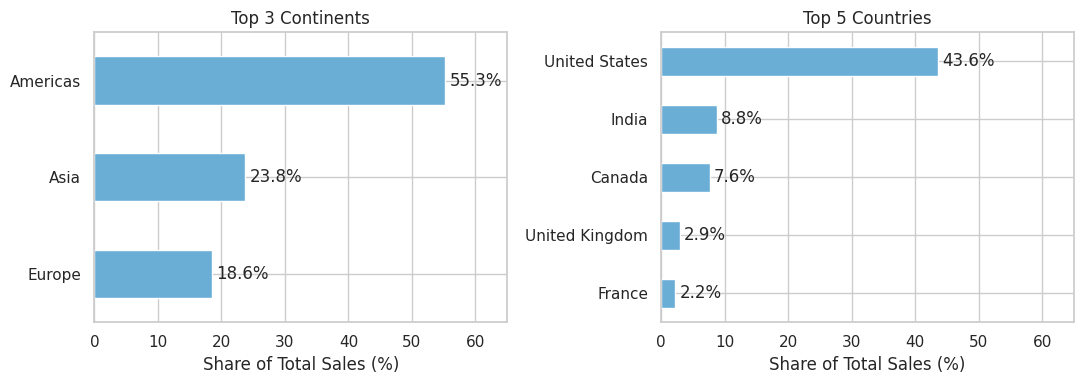

Top Continents by Purchasing Sessions


,Purchasing Sessions
continent,
Americas,18553
Asia,7950
Europe,6261


Top Countries by Purchasing Sessions and Registered Accounts


,Country by Purchases,Purchasing Sessions,Country by Accounts,Registered Accounts
Rank,,,,
1,United States,14673,United States,12384
2,India,3029,India,2687
3,Canada,2560,Canada,2067
4,United Kingdom,1029,United Kingdom,859
5,France,678,France,553


In [ ]:
# Geographic Sales Performance
purchases = df.loc[df["price"].notna()]

continent_sales = purchases.groupby("continent")["price"].sum().nlargest(3)
country_sales = purchases.groupby("country")["price"].sum().nlargest(5)

# Частка від загальних продажів для обох географічних рівнів
total_sales = purchases["price"].sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

for ax, sales, title in zip(
    axes, [continent_sales, country_sales], ["Top 3 Continents", "Top 5 Countries"]):
    share = sales.sort_values() / total_sales * 100
    share.plot.barh(ax=ax)
    ax.set(title=title, xlabel="Share of Total Sales (%)", ylabel="")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

axes[0].set_xlim(0, 65)
plt.tight_layout()
plt.show()

# Кожен рейтинг сортуємо за його власним показником
continent_counts = purchases.groupby("continent")["session_id"].nunique().nlargest(3)
country_counts = purchases.groupby("country")["session_id"].nunique().nlargest(5)
account_counts = df.groupby("country")["account_id"].nunique().nlargest(5)

print("Top Continents by Purchasing Sessions")
display(continent_counts.to_frame("Purchasing Sessions"))

print("Top Countries by Purchasing Sessions and Registered Accounts")
display(pd.DataFrame({
    "Country by Purchases": country_counts.index,
    "Purchasing Sessions": country_counts.values,
    "Country by Accounts": account_counts.index,
    "Registered Accounts": account_counts.values}, index=range(1, 6)).rename_axis("Rank"))

### Geographic Sales Performance

На регіон Americas припало **55.3% усіх продажів**. Серед країн лідирують США: **13.94 млн дол.**, або близько 44% загальної суми. США також посідають перше місце за кількістю сесій із покупкою (14 673) та зареєстрованих акаунтів (12 384).

In [ ]:
# Product Category Performance
top_country = country_sales.idxmax()

global_top = purchases.groupby("product_category")["price"].sum().nlargest(10)
country_top = (
    purchases.loc[purchases["country"].eq(top_country)]
    .groupby("product_category")["price"].sum().nlargest(10))

display(pd.DataFrame({
    "Global Category": global_top.index,
    "Global Sales ($)": global_top.values,
    f"{top_country} Category": country_top.index,
    f"{top_country} Sales ($)": country_top.values}, index=range(1, 11)).rename_axis("Rank").round(2))

,Global Category,Global Sales ($),United States Category,United States Sales ($)
Rank,,,,
1,Sofas & armchairs,8388254.5,Sofas & armchairs,3707144.5
2,Chairs,6147748.8,Chairs,2619773.8
3,Beds,4919725.0,Beds,2213058.0
4,Bookcases & shelving units,3640818.1,Bookcases & shelving units,1567606.9
5,Cabinets & cupboards,2336499.5,Cabinets & cupboards,994545.5
6,Outdoor furniture,2142222.2,Outdoor furniture,929245.2
7,Tables & desks,1790307.5,Tables & desks,777865.0
8,Chests of drawers & drawer units,906562.5,Chests of drawers & drawer units,382388.0
9,Bar furniture,735503.0,Bar furniture,330805.0


### Product Category Performance

У США та у світі збігаються всі десять позицій рейтингу. **Sofas & armchairs, Chairs і Beds** разом забезпечили близько **61% продажів** як у США, так і в загальній вибірці.

In [ ]:
# Sales Acquisition and Technology
def sales_share_ranking(column, limit):
    sales = purchases.groupby(column)["price"].sum().nlargest(limit)
    return [
        f"{name} ({value / total_sales:.1%})"
        for name, value in sales.items()]

display(pd.DataFrame({
    "Device": pd.Series(sales_share_ranking("device", 3)),
    "Recorded Model": pd.Series(sales_share_ranking("mobile_model_name", 5)),
    "Traffic Medium": pd.Series(sales_share_ranking("traffic_source", 5))}).fillna("—").set_axis(range(1, 6)).rename_axis("Rank"))

,Device,Recorded Model,Traffic Medium
Rank,,,
1,desktop (59.0%),Chrome (27.8%),organic (34.2%)
2,mobile (38.7%),<Other> (20.4%),(none) (23.4%)
3,tablet (2.3%),Safari (20.3%),referral (17.6%)
4,—,iPhone (20.1%),<Other> (14.0%)
5,—,ChromeBook (5.7%),(data deleted) (6.4%)


### Sales Acquisition and Technology

На desktop припало **59.0% продажів**, на mobile — **38.7%**. Серед джерел трафіку лідирує `organic` (34.2%). У полі моделі пристрою поруч із `iPhone` трапляються `Chrome` та `Safari`, тому точний розподіл продажів за фізичними моделями визначити складно.

In [ ]:
# Customer Engagement and Purchasing Behavior
accounts = (
    df.dropna(subset=["account_id"])
    .groupby("account_id")
    .agg(sales=("price", "sum"),
         verified=("is_verified", "first"),
         unsubscribed=("is_unsubscribed", "first")))

def account_summary(column, labels):
    summary = accounts.groupby(column)["sales"].agg(["size", "mean"])
    summary.columns = ["Accounts", "Sales per Account ($)"]
    summary["Share of Accounts (%)"] = summary["Accounts"] / len(accounts) * 100
    return summary.rename(index=labels)

display(pd.concat([
    account_summary("verified", {0: "Unverified", 1: "Verified"}),
    account_summary("unsubscribed", {0: "Subscribed", 1: "Unsubscribed"})], keys=["Email Verification", "Subscription"]).round(2))

Accounts  Sales per Account ($)  \
Email Verification Unverified        7909                  90.59   
                   Verified         20036                  93.13   
Subscription       Subscribed       23210                  92.67   
                   Unsubscribed      4735                  91.18   

                                 Share of Accounts (%)  
Email Verification Unverified                    28.30  
                   Verified                      71.70  
Subscription       Subscribed                    83.06  
                   Unsubscribed                  16.94

### Customer Engagement and Purchasing Behavior

Серед 27 945 акаунтів **71.70% підтвердили email**, а **16.94% відписалися від розсилки**. За весь період середні продажі на акаунт становили 92.67 дол. серед підписаних і 91.18 дол. серед тих, хто відписався. Різниця між групами — **1.49 дол. на акаунт**.

# Sales Dynamics Analysis

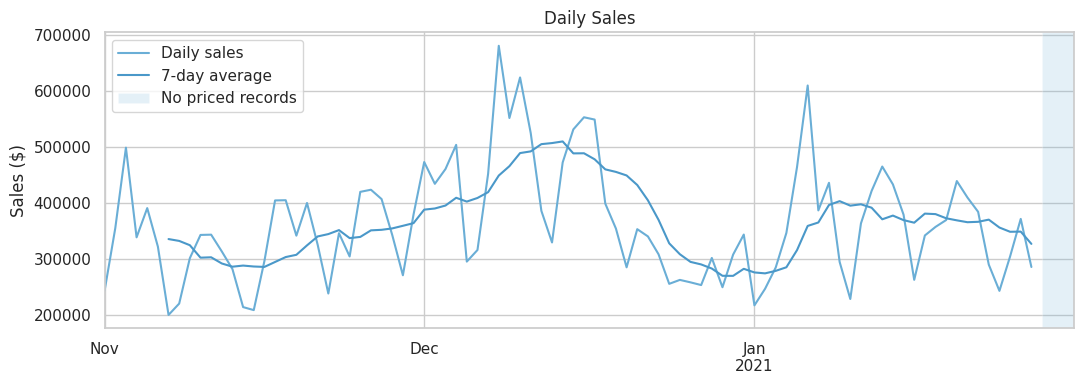

,Recorded Sales ($)
session_date,
2020-11,9897515.0
2020-12,12423439.3
2021-01,9650776.8


In [ ]:
# Overall Sales Trends
daily_sales = df.groupby("session_date")["price"].sum(min_count=1).sort_index()
monthly_sales = daily_sales.groupby(daily_sales.index.to_period("M")).sum()

ax = daily_sales.plot(figsize=(11, 4), label="Daily sales")
daily_sales.rolling(7).mean().plot(ax=ax, label="7-day average")

ax.axvspan(pd.Timestamp("2021-01-28"), pd.Timestamp("2021-01-31"),
           alpha=0.18, label="No priced records")
ax.set(title="Daily Sales", xlabel="", ylabel="Sales ($)")
ax.legend()
plt.tight_layout()
plt.show()

display(monthly_sales.to_frame("Recorded Sales ($)").round(2))

### Overall Sales Trends

Найбільше продажів зафіксовано у **грудні — 12.42 млн дол.**, порівняно з 9.90 млн у листопаді та 9.65 млн у січні. За 28–31 січня відсутні товарні записи з ціною, тому січневий підсумок слід порівнювати з іншими місяцями обережно. Три місяці спостережень не дозволяють встановити річну сезонність.

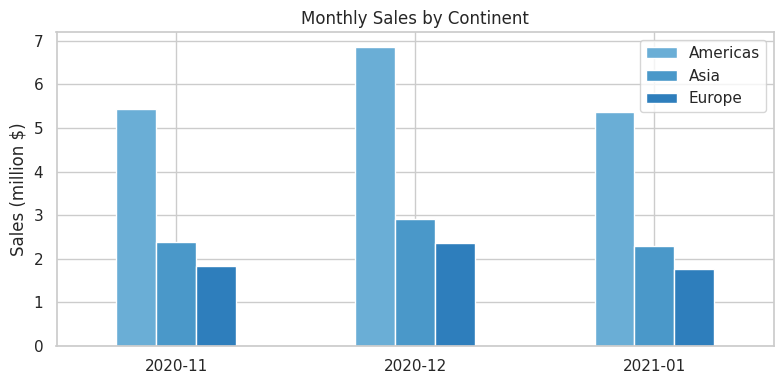

In [ ]:
# Geographic Sales Dynamics
continents = ["Americas", "Asia", "Europe"]
monthly_continent_sales = (
    df.loc[df["continent"].isin(continents)]
    .groupby([df["session_date"].dt.to_period("M"), "continent"])["price"]
    .sum().unstack().reindex(columns=continents))

ax = (monthly_continent_sales / 1_000_000).plot.bar(
    figsize=(8, 4), rot=0)
ax.set(title="Monthly Sales by Continent", xlabel="", ylabel="Sales (million $)")
ax.legend(title="")
plt.tight_layout()
plt.show()

### Geographic Sales Dynamics

У всіх трьох регіонах найбільшу суму продажів зафіксовано в грудні. Найбільший абсолютний приріст від листопада до грудня припав на **Americas — близько 1.42 млн дол.**, порівняно з 0.51 млн в Азії та 0.52 млн у Європі.

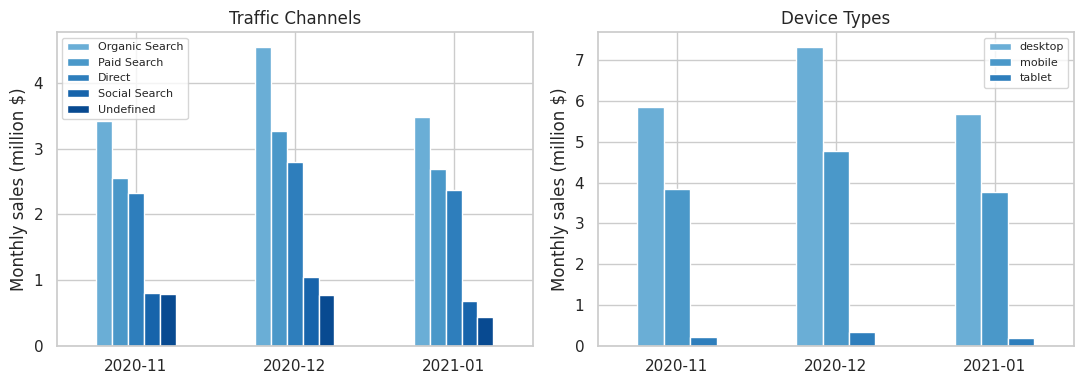

2020-11: Organic Search / desktop
2020-12: Organic Search / desktop
2021-01: Organic Search / desktop


In [ ]:
# Sales Dynamics by Acquisition and Technology
month = df["session_date"].dt.to_period("M")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, column, title in zip(
    axes, ["traffic_channel", "device"], ["Traffic Channels", "Device Types"]):
    monthly = df.groupby([month, column])["price"].sum().unstack(fill_value=0)
    monthly = monthly[monthly.sum().sort_values(ascending=False).index]
    monthly.index = monthly.index.astype(str)

    (monthly / 1_000_000).plot.bar(ax=ax, rot=0)
    ax.set(title=title, xlabel="", ylabel="Monthly sales (million $)")
    ax.legend(title="", fontsize=8)

plt.tight_layout()
plt.show()

for period, group in df.groupby(month):
    channel = group.groupby("traffic_channel")["price"].sum().idxmax()
    device = group.groupby("device")["price"].sum().idxmax()
    print(f"{period}: {channel} / {device}")

### Sales Dynamics by Acquisition and Technology

У кожному з трьох місяців найбільша сума продажів серед каналів трафіку припадала на **Organic Search**, а серед типів пристроїв — на **desktop**. Обидва зберегли перше місце і в грудні, коли загальні продажі досягли піку.

# Pivot Table Analysis

In [ ]:
# Traffic Channel × Device

# Залишаємо сесії з відомим каналом трафіку та типом пристрою
pivot_data = df.dropna(subset=["traffic_channel", "device", "session_id"])
unknown_labels = ["Undefined", "(not set)"]

pivot_data = pivot_data.loc[
    ~pivot_data["traffic_channel"].isin(unknown_labels)
    & ~pivot_data["device"].isin(unknown_labels)]

# Рахуємо унікальні сесії за каналом і типом пристрою
traffic_device_pivot = pivot_data.pivot_table(
    index="traffic_channel",
    columns="device",
    values="session_id",
    aggfunc="nunique",
    fill_value=0,
    margins=True,
    margins_name="Total")

display(traffic_device_pivot)

device,desktop,mobile,tablet,Total
traffic_channel,,,,
Direct,47825,31745,1812,81382
Organic Search,72622,49014,2789,124425
Paid Search,55167,37034,2140,94341
Social Search,16288,10988,638,27914
Total,191902,128781,7379,328062


### Traffic Channel × Device

Серед **328 062 сесій** із відомим каналом трафіку та типом пристрою найбільше припало на **Organic Search — 124 425 (37,9%)**. У кожному з чотирьох каналів desktop посідає перше місце за кількістю сесій, mobile — друге, tablet — третє.

In [ ]:
# Product Category × Country

# Виключаємо записи без категорії, країни або ціни
sales_data = df.dropna(
    subset=["product_category", "country", "price"])

# Визначаємо топ-10 категорій
top_10_categories = (
    sales_data.groupby("product_category")["price"]
    .sum()
    .nlargest(10)
    .index)

# Визначаємо топ-5 країн
top_5_countries = (
    sales_data.groupby("country")["price"]
    .sum()
    .nlargest(5)
    .index)

# Фільтруємо дані
top_sales_data = sales_data[
    sales_data["product_category"].isin(top_10_categories)
    & sales_data["country"].isin(top_5_countries)]

# Створюємо зведену таблицю
category_country_pivot = pd.pivot_table(
    top_sales_data,
    index="product_category",
    columns="country",
    values="price",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total")

print("Sales by Product Category and Country ($):")
display(category_country_pivot)

Sales by Product Category and Country ($):


country,Canada,France,India,United Kingdom,United States,Total
product_category,,,,,,
Bar furniture,51724.0,11199.0,57657.0,22103.0,330805.0,473488.0
Beds,354772.0,116414.0,358319.5,133816.0,2213058.0,3176379.5
Bookcases & shelving units,278981.9,73830.0,364507.4,113987.6,1567606.9,2398913.8
Cabinets & cupboards,181802.0,59101.5,191888.0,71684.5,994545.5,1499021.5
Chairs,417740.8,134029.4,544309.2,188519.4,2619773.8,3904372.6
Chests of drawers & drawer units,71952.0,21544.5,73111.0,36784.0,382388.0,585779.5
Children's furniture,30264.0,14258.0,39177.0,13348.0,207575.0,304622.0
Outdoor furniture,185322.8,40486.4,162289.4,57002.4,929245.2,1374346.2
Sofas & armchairs,692427.5,187735.0,788430.0,234812.0,3707144.5,5610549.0


### Product Category × Country

Продажі десяти вибраних категорій у п’яти країнах становили **20,52 млн дол.**, з яких **13,73 млн дол. припало на США**. У всіх п’яти країнах за сумою продажів лідирує **Sofas & armchairs**, а друге місце посідає **Chairs**. Третє місце в Індії займає **Bookcases & shelving units**, у решті чотирьох країн — **Beds**.

In [ ]:
# Monthly Sales × Continent

# Копія даних для аналізу
monthly_data = df.dropna(
    subset=["session_date", "continent", "price"]).copy()

# Виділяємо місяць
monthly_data["month"] = (
    monthly_data["session_date"].dt.to_period("M").astype(str))

# Створюємо зведену таблицю
monthly_continent_pivot = pd.pivot_table(
    monthly_data,
    index="month",
    columns="continent",
    values="price",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total")

print("Monthly Sales by Continent ($):")
display(monthly_continent_pivot)

Monthly Sales by Continent ($):


continent,(not set),Africa,Americas,Asia,Europe,Oceania,Total
month,,,,,,,
2020-11,28056.4,86136.5,5439027.9,2393234.6,1825299.1,125760.5,9897515.0
2020-12,36250.0,135711.1,6854446.4,2905399.6,2349627.6,142004.6,12423439.3
2021-01,9761.0,109383.4,5371805.7,2302664.1,1759697.5,97465.1,9650776.8
Total,74067.4,331231.0,17665280.0,7601298.3,5934624.2,365230.2,31971731.1


### Monthly Sales × Continent

Частка регіону **Americas** у зафіксованих продажах залишалася стабільною: **55,0% у листопаді, 55,2% у грудні та 55,7% у січні**. Отже, навіть у грудні, коли загальна сума продажів зросла, на Americas припадала майже така сама частка, як і в листопаді.

In [ ]:
# Traffic Source × Product Category

# Виключаємо записи без джерела трафіку, категорії товару або ціни
traffic_category_data = df.dropna(
    subset=["traffic_source", "product_category", "price"])

# Визначаємо топ-5 джерел трафіку
top_5_sources = (
    traffic_category_data.groupby("traffic_source")["price"]
    .sum()
    .nlargest(5)
    .index)

# Визначаємо топ-10 категорій товарів
top_10_categories = (
    traffic_category_data.groupby("product_category")["price"]
    .sum()
    .nlargest(10)
    .index)

# Залишаємо тільки вибрані джерела та категорії
filtered_traffic_category = traffic_category_data[
    traffic_category_data["traffic_source"].isin(top_5_sources)
    & traffic_category_data["product_category"].isin(top_10_categories)]

# Створюємо зведену таблицю
traffic_category_pivot = pd.pivot_table(
    filtered_traffic_category,
    index="product_category",
    columns="traffic_source",
    values="price",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total")

print("Sales by Traffic Source and Product Category ($):")
display(traffic_category_pivot)

Sales by Traffic Source and Product Category ($):


traffic_source,(data deleted),(none),<Other>,organic,referral,Total
product_category,,,,,,
Bar furniture,56850.0,164452.0,104871.0,251288.0,136075.0,713536.0
Beds,316556.0,1130173.0,687293.0,1681080.0,834907.5,4650009.5
Bookcases & shelving units,225594.2,833634.1,517895.4,1245685.3,664505.3,3487314.3
Cabinets & cupboards,126427.0,549938.5,314359.5,820149.5,436465.0,2247339.5
Chairs,365622.2,1454728.0,893187.8,2092726.0,1058901.8,5865165.8
Chests of drawers & drawer units,69597.5,210388.0,127967.5,302321.0,167180.5,877454.5
Children's furniture,28704.0,117089.0,61644.0,156090.0,76765.0,440292.0
Outdoor furniture,149924.6,542934.8,319576.4,692003.6,331406.6,2035846.0
Sofas & armchairs,559646.0,1990622.0,1134287.0,2857025.0,1548783.5,8090363.5


### Traffic Source × Product Category

У межах вибірки з десяти товарних категорій і п’яти джерел трафіку найбільша сума продажів припала на `organic` — **10,76 млн дол. із 30,13 млн дол.** Категорія **Sofas & armchairs** лідирувала в кожному з п’яти джерел. Найбільша сума для окремої пари «джерело — категорія» також припала на `organic` і `Sofas & armchairs` — **2,86 млн дол.**

# Correlation Analysis

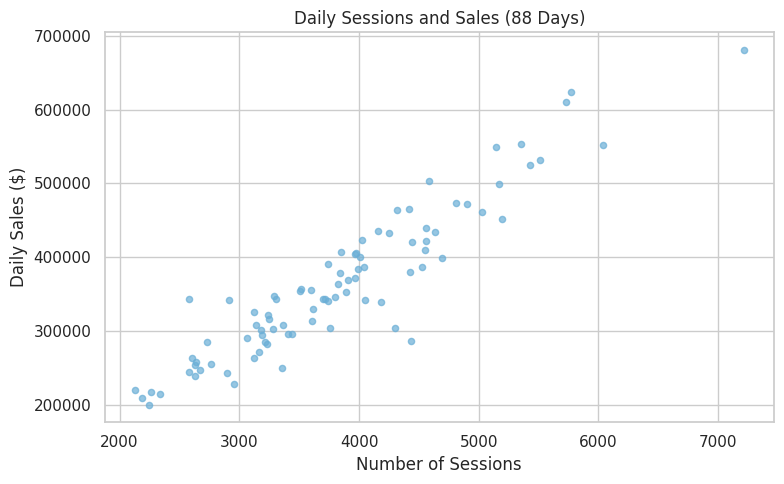

,Days,Pearson r,Pearson p,Spearman rho,Spearman p
Scenario,,,,,
Days with recorded sales,88,0.9313,1.74e-39,0.9043,1.54e-33
"All days, missing sales set to zero",92,0.7911,6.48e-21,0.8653,9.76e-29


In [ ]:
# Щоденні сесії та продажі
by_date = df.groupby("session_date")
daily_metrics = pd.DataFrame({
    "sessions": by_date["session_id"].nunique(),
    "sales": by_date["price"].sum(min_count=1)})

# На графіку показуємо дні, для яких відома сума продажів
observed = daily_metrics.dropna(subset=["sales"])

ax = observed.plot.scatter(
    x="sessions", y="sales", figsize=(8, 5),
    alpha=0.7)
ax.set(
    title=f"Daily Sessions and Sales ({len(observed)} Days)",
    xlabel="Number of Sessions",
    ylabel="Daily Sales ($)")
plt.tight_layout()
plt.show()

# Перевіряємо, як чотири дні без цін впливають на кореляцію
scenarios = {
    "Days with recorded sales": observed,
    "All days, missing sales set to zero": daily_metrics.fillna({"sales": 0})}

results = []
for scenario, data in scenarios.items():
    r, p_r = stats.pearsonr(data["sessions"], data["sales"])
    rho, p_rho = stats.spearmanr(data["sessions"], data["sales"])
    results.append({
        "Scenario": scenario,
        "Days": len(data),
        "Pearson r": r,
        "Pearson p": p_r,
        "Spearman rho": rho,
        "Spearman p": p_rho})

display(pd.DataFrame(results).set_index("Scenario").style.format({
    "Pearson r": "{:.4f}", "Pearson p": "{:.2e}",
    "Spearman rho": "{:.4f}", "Spearman p": "{:.2e}"}))

### Daily Sessions and Sales Correlation

За 88 днів із зафіксованими продажами більша кількість сесій зазвичай супроводжувалася більшою сумою продажів. Зв’язок був сильним і позитивним за обома коефіцієнтами: **r Пірсона = 0,9313**, **ρ Спірмена = 0,9043** (в обох випадках p < 0,001).

Якщо припустити, що 28–31 січня продажі дорівнювали нулю, обидва коефіцієнти знижуються: r Пірсона — до **0,7911**, ρ Спірмена — до **0,8653**. Висновок про сильний позитивний зв’язок зберігається, хоча оцінка Пірсона помітніше залежить від припущення щодо цих чотирьох днів.

,Pearson r,p-value
Pair,,
Americas / Asia,0.6923,8.00e-14
Americas / Europe,0.6695,9.91e-13
Asia / Europe,0.6678,1.19e-12


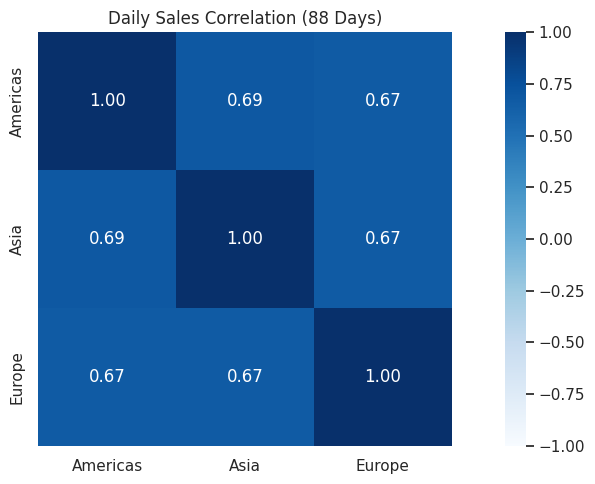

In [ ]:
# Топ-3 континенти за сумою продажів
top_continents = df.groupby("continent")["price"].sum().nlargest(3).index

# Ті самі дати, що й в основному аналізі сесій і продажів
daily_continent_sales = (
    df.pivot_table(
        index="session_date", columns="continent",
        values="price", aggfunc="sum", fill_value=0)
    .loc[observed.index, top_continents])

# Кореляція Пірсона для кожної пари континентів
from itertools import combinations

results = []
for first, second in combinations(top_continents, 2):
    r, p = stats.pearsonr(daily_continent_sales[first], daily_continent_sales[second])
    results.append({"Pair": f"{first} / {second}", "Pearson r": r, "p-value": p})

display(pd.DataFrame(results).set_index("Pair").style.format({
    "Pearson r": "{:.4f}", "p-value": "{:.2e}"}))

plt.figure(figsize=(11, 5))
sns.heatmap(
    daily_continent_sales.corr(), annot=True, fmt=".2f",
    cmap="Blues", vmin=-1, vmax=1, center=0, square=True)
plt.title(f"Daily Sales Correlation ({len(daily_continent_sales)} Days)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Sales Correlation Across Top 3 Continents

За 88 днів із зафіксованими продажами денні суми продажів у трьох регіонах зазвичай змінювалися в одному напрямку. Кореляції Пірсона були близькими за величиною: **Americas / Asia — 0,6923**, **Americas / Europe — 0,6695**, **Asia / Europe — 0,6678**. Для всіх трьох пар p < 0,001.

,Pearson r,p-value
Pair,,
Organic Search / Paid Search,0.8082,1.76e-21
Direct / Organic Search,0.7599,9.11e-18
Direct / Paid Search,0.7243,1.51e-15
Direct / Social Search,0.4619,5.90e-06
Paid Search / Social Search,0.4523,9.70e-06
Organic Search / Social Search,0.4344,2.35e-05


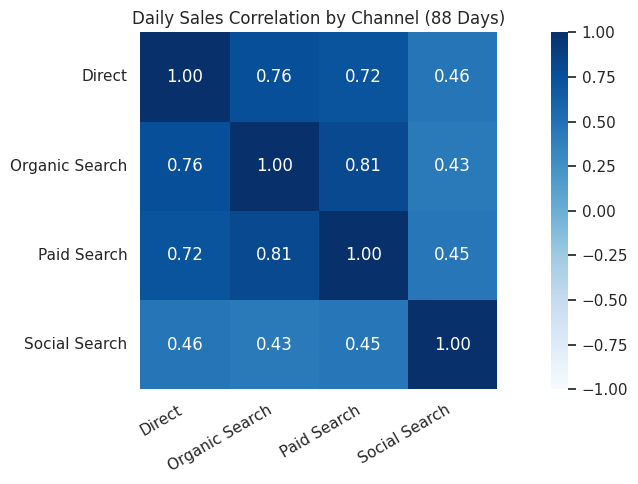

In [ ]:
# Щоденні продажі за відомими каналами трафіку
channel_data = df.dropna(subset=["traffic_channel"])
channel_data = channel_data.loc[
    ~channel_data["traffic_channel"].isin(["Undefined", "(not set)"])]

daily_channel_sales = (
    channel_data.pivot_table(
        index="session_date", columns="traffic_channel",
        values="price", aggfunc="sum", fill_value=0)
    .reindex(observed.index, fill_value=0))

# Кореляція Пірсона для кожної пари каналів
results = []
for first, second in combinations(daily_channel_sales.columns, 2):
    r, p = stats.pearsonr(daily_channel_sales[first], daily_channel_sales[second])
    results.append({"Pair": f"{first} / {second}", "Pearson r": r, "p-value": p})

channel_results = pd.DataFrame(results).sort_values("Pearson r", ascending=False)
display(channel_results.set_index("Pair").style.format({
    "Pearson r": "{:.4f}", "p-value": "{:.2e}"}))

plt.figure(figsize=(11, 5))
sns.heatmap(
    daily_channel_sales.corr(), annot=True, fmt=".2f",
    cmap="Blues", vmin=-1, vmax=1, center=0, square=True)
plt.title(f"Daily Sales Correlation by Channel ({len(daily_channel_sales)} Days)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Sales Correlation Across Traffic Channels

За 88 днів із зафіксованими продажами найсильніший зв’язок спостерігався між щоденними продажами через **Organic Search і Paid Search** (r = 0,8082). Продажі через Direct також тісно корелювали з продажами через обидва пошукові канали (r від 0,7243 до 0,7599).

Для Social Search зв’язки з рештою каналів були помірними (r від 0,4344 до 0,4619). Усі шість кореляцій були позитивними та статистично значущими (p < 0,001).

,Pearson r,p-value
Pair,,
Sofas & armchairs / Bookcases & shelving units,0.6662,1.41e-12
Sofas & armchairs / Cabinets & cupboards,0.6576,3.42e-12
Chairs / Bookcases & shelving units,0.6371,2.50e-11
Beds / Bookcases & shelving units,0.5929,1.15e-09
Sofas & armchairs / Chairs,0.5782,3.64e-09
Chairs / Cabinets & cupboards,0.5729,5.47e-09
Chairs / Beds,0.5545,2.08e-08
Bookcases & shelving units / Cabinets & cupboards,0.5394,5.87e-08
Sofas & armchairs / Beds,0.5354,7.69e-08


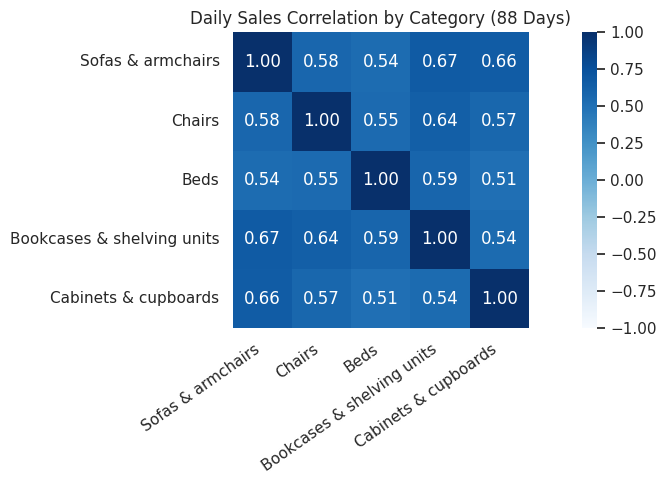

In [ ]:
# Топ-5 категорій за сумою продажів
top_categories = df.groupby("product_category")["price"].sum().nlargest(5).index

# Щоденні продажі категорій за 88 днів із товарними записами
category_data = df.loc[df["product_category"].isin(top_categories)]
daily_category_sales = (
    category_data.pivot_table(
        index="session_date", columns="product_category",
        values="price", aggfunc="sum", fill_value=0)
    .reindex(index=observed.index, columns=top_categories, fill_value=0))

# Кореляція Пірсона для кожної з десяти пар
results = []
for first, second in combinations(top_categories, 2):
    r, p = stats.pearsonr(daily_category_sales[first], daily_category_sales[second])
    results.append({"Pair": f"{first} / {second}", "Pearson r": r, "p-value": p})

category_results = pd.DataFrame(results).sort_values("Pearson r", ascending=False)
display(category_results.set_index("Pair").style.format({
    "Pearson r": "{:.4f}", "p-value": "{:.2e}"}))

plt.figure(figsize=(11, 5))
sns.heatmap(
    daily_category_sales.corr(), annot=True, fmt=".2f",
    cmap="Blues", vmin=-1, vmax=1, center=0, square=True)
plt.title(f"Daily Sales Correlation by Category ({len(daily_category_sales)} Days)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Sales Correlation Across Top 5 Product Categories

За 88 днів із зафіксованими продажами п’ять провідних категорій мали позитивні кореляції в усіх десяти парах (p < 0,001). Найтісніше змінювалися разом щоденні суми продажів **Sofas & armchairs і Bookcases & shelving units** (r = 0,6662). Найслабший зв’язок спостерігався між **Beds і Cabinets & cupboards** (r = 0,5146).

,Pearson r,p-value
Pair,,
desktop / mobile,0.8057,2.90e-21
desktop / tablet,0.5385,6.26e-08
mobile / tablet,0.4958,9.05e-07


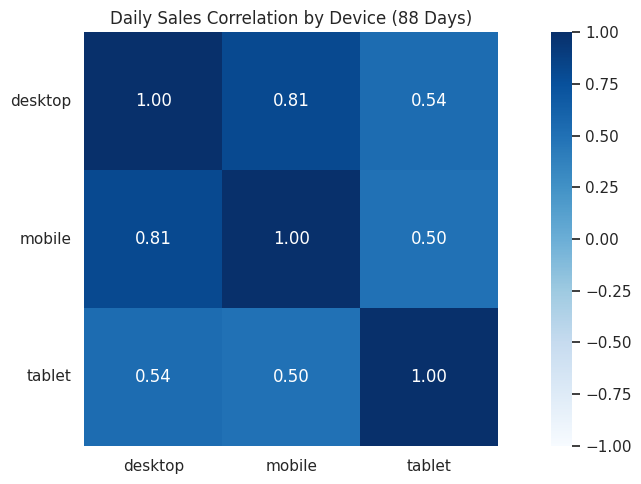

In [ ]:
# Щоденні продажі за типами пристроїв
daily_device_sales = (
    df.pivot_table(
        index="session_date", columns="device",
        values="price", aggfunc="sum", fill_value=0)
    .loc[observed.index, ["desktop", "mobile", "tablet"]])

# Кореляція Пірсона для трьох пар пристроїв
results = []
for first, second in combinations(daily_device_sales.columns, 2):
    r, p = stats.pearsonr(daily_device_sales[first], daily_device_sales[second])
    results.append({"Pair": f"{first} / {second}", "Pearson r": r, "p-value": p})

device_results = pd.DataFrame(results).sort_values("Pearson r", ascending=False)
display(device_results.set_index("Pair").style.format({
    "Pearson r": "{:.4f}", "p-value": "{:.2e}"}))

plt.figure(figsize=(11, 5))
sns.heatmap(
    daily_device_sales.corr(), annot=True, fmt=".2f",
    cmap="Blues", vmin=-1, vmax=1, center=0, square=True)
plt.title(f"Daily Sales Correlation by Device ({len(daily_device_sales)} Days)")
plt.xlabel("")
plt.ylabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Device Sales Correlation

За 88 днів із зафіксованими продажами найсильніша позитивна кореляція спостерігалася між щоденними продажами на **desktop і mobile** (r = 0,8057). Продажі на tablet також позитивно корелювали з продажами на desktop (r = 0,5385) і mobile (r = 0,4958), але обидва зв’язки були помірними. Усі три кореляції були статистично значущими (p < 0,001).

# Statistical Analysis of Differences Between Groups

,Days,Mean ($),Q1 ($),Median ($),Q3 ($)
account_status,,,,,
Linked account,88,29346.80,20717.38,28048.00,35774.70
No linked account,88,333968.32,270485.50,316724.25,379948.48


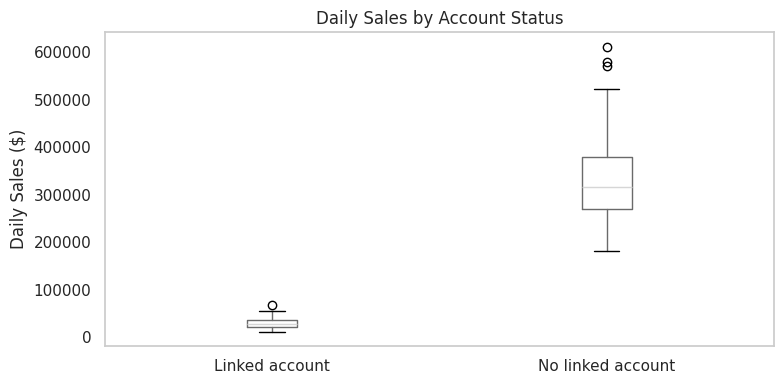

Median paired difference ($): 292,176.30
Wilcoxon statistic: 0.0
P-value: 3.73e-16


In [ ]:
# Щоденні продажі сесій із прив’язаним акаунтом і без нього
account_status = np.where(
    df["account_id"].notna(), "Linked account", "No linked account")

daily_group_sales = (
    df.assign(account_status=account_status)
    .pivot_table(
        index="session_date", columns="account_status",
        values="price", aggfunc="sum", fill_value=0)
    .loc[observed.index, ["Linked account", "No linked account"]])

# Розподіл денних продажів у кожній групі
summary = daily_group_sales.describe().T[["count", "mean", "25%", "50%", "75%"]]
summary.columns = ["Days", "Mean ($)", "Q1 ($)", "Median ($)", "Q3 ($)"]
display(summary.astype({"Days": int}).round(2))

ax = daily_group_sales.boxplot(figsize=(8, 4), grid=False)
ax.set(title="Daily Sales by Account Status", xlabel="", ylabel="Daily Sales ($)")
plt.tight_layout()
plt.show()

# Парне порівняння: для кожної дати обчислюємо різницю між групами
daily_difference = (
    daily_group_sales["No linked account"] - daily_group_sales["Linked account"])
statistic, p_value = stats.wilcoxon(daily_difference, alternative="two-sided")

print(f"Median paired difference ($): {daily_difference.median():,.2f}")
print(f"Wilcoxon statistic: {statistic:.1f}")
print(f"P-value: {p_value:.2e}")

### Daily Sales by Account Status

За 88 днів із зафіксованими продажами медіана денних продажів становила **316,7 тис. дол.** для сесій без прив’язаного акаунта та **28,0 тис. дол.** для сесій із прив’язаним акаунтом. При порівнянні груп за однакові дати медіана денної різниці становила **292,2 тис. дол.** на користь сесій без прив’язаного акаунта.

Парний критерій Вілкоксона показав статистично значущу різницю (W = 0, p < 0,001). Результат стосується сумарних продажів кожної групи за день. На ці суми впливає й розмір груп: за весь період 92,01% сесій не мали прив’язаного акаунта.

,Mean Sessions per Day,Median Sessions per Day
traffic_channel,,
Organic Search,1352.4,1329.0
Paid Search,1025.4,989.0
Direct,884.6,869.5
Social Search,303.4,308.0


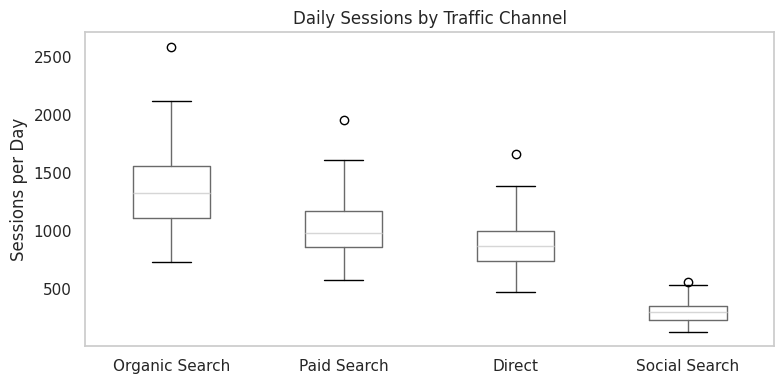

Days compared: 92
Friedman statistic: 276.00
P-value: 1.55e-59


In [ ]:
# Щоденна кількість унікальних сесій за відомими каналами
channels = ["Organic Search", "Paid Search", "Direct", "Social Search"]
all_dates = df["session_date"].dropna().sort_values().unique()

traffic_sessions = (
    df.loc[df["traffic_channel"].isin(channels)]
    .groupby(["session_date", "traffic_channel"])["session_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=all_dates, columns=channels, fill_value=0))

# Типовий денний обсяг трафіку для кожного каналу
summary = traffic_sessions.agg(["mean", "median"]).T
summary.columns = ["Mean Sessions per Day", "Median Sessions per Day"]
display(summary.round(1))

ax = traffic_sessions.boxplot(figsize=(8, 4), grid=False)
ax.set(title="Daily Sessions by Traffic Channel", xlabel="", ylabel="Sessions per Day")
plt.tight_layout()
plt.show()

# Кожна дата об’єднує чотири спостереження в один блок
statistic, p_value = stats.friedmanchisquare(
    *(traffic_sessions[channel] for channel in channels))

print(f"Days compared: {len(traffic_sessions)}")
print(f"Friedman statistic: {statistic:.2f}")
print(f"P-value: {p_value:.2e}")

### Sessions by Traffic Channel

Протягом усіх 92 днів порядок чотирьох каналів за кількістю сесій був однаковим. Лідирував **Organic Search** (медіана — 1 329 сесій на день), далі йшли **Paid Search** (989), **Direct** (869,5) і **Social Search** (308).

Критерій Фрідмана з порівнянням каналів у межах кожної дати виявив статистично значущу загальну відмінність між каналами (χ² = 276,00, df = 3, p < 0,001).

In [ ]:
# Відбираємо Europe та Americas
organic_data = df[
    df["continent"].isin(["Europe", "Americas"])].dropna(subset=["traffic_source"])

# Створюємо ознаку органічного трафіку
organic_data["is_organic"] = (
    organic_data["traffic_source"] == "organic")

# Формуємо таблицю частот
organic_pivot = pd.crosstab(
    organic_data["continent"],
    organic_data["is_organic"])

organic_pivot.columns = ["Non-organic", "Organic"]

print("Organic Traffic Sessions by Continent:")
display(organic_pivot)

# Розраховуємо частку органічного трафіку
organic_share = (
    organic_pivot["Organic"] / organic_pivot.sum(axis=1) * 100)

print("\nOrganic Traffic Share (%):")
display(organic_share.round(2))

# Критерій хі-квадрат Пірсона
chi2_stat, p_value, dof, expected = chi2_contingency(
    organic_pivot)

print("\nChi-square Test:")
print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

Organic Traffic Sessions by Continent:


,Non-organic,Organic
continent,,
Americas,127396,65783
Europe,42945,22190



Organic Traffic Share (%):


,0
continent,
Americas,34.05
Europe,34.07



Chi-square Test:
Chi-square statistic: 0.0041
Degrees of freedom: 1
P-value: 0.948734
Result: No statistically significant difference.


### Organic Traffic: Europe vs. Americas

Частка сесій, позначених як `organic` у полі `traffic_source`, становила **34,07% у Європі** та **34,05% у регіоні Americas**. Спостережувана різниця — близько **0,02 відсоткового пункта**. Критерій хі-квадрат не виявив статистично значущої відмінності між регіонами (χ² = 0,0041, p = 0,9487).

,Mean Daily Sales ($),Median Daily Sales ($)
continent,,
Americas,200741.82,188963.45
Asia,86378.39,80045.85
Europe,67438.91,66325.20
Oceania,4150.34,2787.50
Africa,3763.99,2400.00


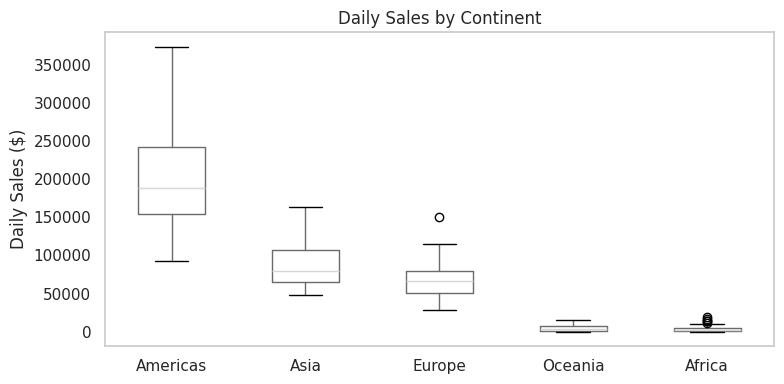

Days compared: 88
Friedman statistic: 325.68
P-value: 3.12e-69


In [ ]:
# Щоденні продажі у п’яти географічних регіонах
regions = ["Americas", "Asia", "Europe", "Oceania", "Africa"]

region_daily_sales = (
    df.loc[df["continent"].isin(regions)]
    .pivot_table(
        index="session_date", columns="continent",
        values="price", aggfunc="sum", fill_value=0)
    .reindex(index=observed.index, columns=regions, fill_value=0))

# Середні та медіанні продажі за день
summary = region_daily_sales.agg(["mean", "median"]).T
summary.columns = ["Mean Daily Sales ($)", "Median Daily Sales ($)"]
display(summary.round(2))

ax = region_daily_sales.boxplot(figsize=(8, 4), grid=False)
ax.set(title="Daily Sales by Continent", xlabel="", ylabel="Daily Sales ($)")
plt.tight_layout()
plt.show()

# Порівнюємо регіони в межах однакових дат
statistic, p_value = stats.friedmanchisquare(
    *(region_daily_sales[region] for region in regions))

print(f"Days compared: {len(region_daily_sales)}")
print(f"Friedman statistic: {statistic:.2f}")
print(f"P-value: {p_value:.2e}")

### Sales by Continent

За 88 днів із зафіксованими продажами найвища медіана денних продажів була в регіоні **Americas — 189,0 тис. дол.** Це більш ніж удвічі перевищує медіану Азії (80,0 тис. дол.). Далі йдуть Європа (66,3 тис.), Океанія (2,8 тис.) та Африка (2,4 тис.).

Порівняння п’яти регіонів за однаковими датами виявило статистично значущу загальну відмінність у щоденних продажах (критерій Фрідмана: χ² = 325,68, df = 4, p < 0,001).

In [ ]:
# Сесії за дати, для яких у вибірці є зафіксовані продажі
device_data = df.loc[
    df["session_date"].isin(observed.index)
    & df["device"].isin(["desktop", "mobile", "tablet"]),
    ["device", "price"]].copy()

device_data["purchase"] = device_data["price"].notna()

# Кількість і частка сесій із покупкою для кожного пристрою
counts = pd.crosstab(device_data["device"], device_data["purchase"])
counts = counts.reindex(columns=[False, True], fill_value=0)
counts.columns = ["No Purchase", "Purchase"]

summary = counts.copy()
summary["Total Sessions"] = counts.sum(axis=1)
summary["Purchase Share (%)"] = counts["Purchase"] / summary["Total Sessions"] * 100
display(summary.round(2))

# Перевіряємо зв’язок між типом пристрою та наявністю покупки
chi2, p_value, dof, _ = chi2_contingency(counts)
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")

,No Purchase,Purchase,Total Sessions,Purchase Share (%)
device,,,,
desktop,176875,19702,196577,10.02
mobile,118842,13113,131955,9.94
tablet,6821,723,7544,9.58


Chi-square statistic: 1.9797
Degrees of freedom: 2
P-value: 0.3716


### Device Type and Purchase Activity

За 88 днів із зафіксованими продажами частка сесій із покупкою становила **10,02% на desktop**, **9,94% на mobile** та **9,58% на tablet**. Різниця між найвищою та найнижчою частками становила близько **0,44 відсоткового пункта**.

Критерій хі-квадрат не виявив статистично значущого зв’язку між типом пристрою та наявністю покупки в сесії (χ² = 1,98, df = 2, p = 0,3716).

# Overall Conclusion

З 1 листопада 2020 року до 31 січня 2021 року зафіксовано **349 545 сесій і 31,97 млн дол. продажів**. США були найбільшим ринком із часткою близько 44% загальної суми. Три категорії — Sofas & armchairs, Chairs і Beds — забезпечили близько 61% продажів як у США, так і в усій вибірці.

Найбільшу місячну суму продажів зафіксовано **у грудні — 12,42 млн дол.** Organic Search лідирував за сумою продажів серед каналів у кожному з трьох місяців. Січневий підсумок слід оцінювати з урахуванням того, що 28–31 січня сесії реєструвалися, але товарні записи з ціною були відсутні.

За 88 днів із зафіксованими продажами дні з більшою кількістю сесій зазвичай мали й вищу суму продажів (коефіцієнт Пірсона r = 0,93). На desktop припало **59% суми продажів**. Водночас частка сесій із покупкою була близькою на desktop (10,02%) і mobile (9,94%), а на tablet становила 9,58%. Статистично значущого зв’язку між типом пристрою та наявністю покупки в сесії не виявлено (p = 0,3716).

Dashboard on Tableau Public:

№1 https://public.tableau.com/app/profile/oleksandra.karpalova/viz/Book2_17946961792440/E-commerceTrafficSalesOverview?publish=yes

№2 https://public.tableau.com/app/profile/oleksandra.karpalova/viz/Book2_17946961792440/SalesbyCountryProductCategory?publish=yes